# 01 — Exploratory Data Analysis (EDA)

**EPFL CS-433 Machine Learning (Fall 2026) — Project 1**

**Objective:** Uncover dataset structure, missingness patterns, CDC survey encoding traps, and target leakages in the CDC BRFSS 2015 dataset to design a leak-free preprocessing pipeline.

**Author:** Zhihao Chen

In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")  # import project modules from repo root

import os
import numpy as np
import matplotlib.pyplot as plt

from helpers import load_csv_data, create_csv_submission
import implementations as impl
import preprocessing as prep
import metrics
import cross_validation as cv

DATA_PATH = "../data/dataset"
SEED = 42
np.random.seed(SEED)

os.makedirs("../report/figures", exist_ok=True)
print("Environment initialized successfully.")

Environment initialized successfully.


## 1. Load Data
We inspect the training set using the fast streaming parser from `preprocessing.py` and inspect feature names.

In [2]:
feature_names = prep.load_feature_names(DATA_PATH)
print(f"Total features in CSV header (excluding Id): {len(feature_names)}")
print(f"First 10 features: {feature_names[:10]}")
print(f"Last 10 features: {feature_names[-10:]}")

# Load cached preprocessed data
x_train_clean = np.load("../data/processed/x_train.npy")
y_train = np.load("../data/processed/y_train.npy")
print(f"Sanitized feature matrix shape: {x_train_clean.shape}, y shape: {y_train.shape}")

Total features in CSV header (excluding Id): 321
First 10 features: ['_STATE', 'FMONTH', 'IDATE', 'IMONTH', 'IDAY', 'IYEAR', 'DISPCODE', 'SEQNO', '_PSU', 'CTELENUM']
Last 10 features: ['_PAREC1', '_PASTAE1', '_LMTACT1', '_LMTWRK1', '_LMTSCL1', '_RFSEAT2', '_RFSEAT3', '_FLSHOT6', '_PNEUMO2', '_AIDTST3']
Sanitized feature matrix shape: (328135, 197), y shape: (328135,)


## 2. Labels and Class Imbalance
The target variable `_MICHD` indicates whether the respondent reported having coronary heart disease or myocardial infarction (heart attack). Let us analyze the class distribution.

In [3]:
n_total = len(y_train)
n_pos = int(np.sum(y_train == 1))
n_neg = int(np.sum(y_train == -1))
pos_rate = n_pos / n_total

print(f"Total Respondents: {n_total:,}")
print(f"Negative Class (-1): {n_neg:,} ({n_neg / n_total:.2%})")
print(f"Positive Class (+1): {n_pos:,} ({pos_rate:.2%})")
print(f"Imbalance Ratio: {n_neg / n_pos:.2f} : 1")

# Evaluate the trivial 'always -1' majority classifier
dummy_pred = np.full(n_total, -1)
dummy_acc = metrics.accuracy(y_train, dummy_pred)
dummy_p, dummy_r, dummy_f1 = metrics.precision_recall_f1(y_train, dummy_pred)
print("\n--- Trivial Majority Predictor (Always -1) ---")
print(f"Accuracy:  {dummy_acc:.4f} (91.17%)")
print(f"Precision: {dummy_p:.4f}")
print(f"Recall:    {dummy_r:.4f}")
print(f"F1-Score:  {dummy_f1:.4f} (Zero positive detection)")

Total Respondents: 328,135
Negative Class (-1): 299,160 (91.17%)
Positive Class (+1): 28,975 (8.83%)
Imbalance Ratio: 10.32 : 1

--- Trivial Majority Predictor (Always -1) ---
Accuracy:  0.9117 (91.17%)
Precision: 0.0000
Recall:    0.0000
F1-Score:  0.0000 (Zero positive detection)


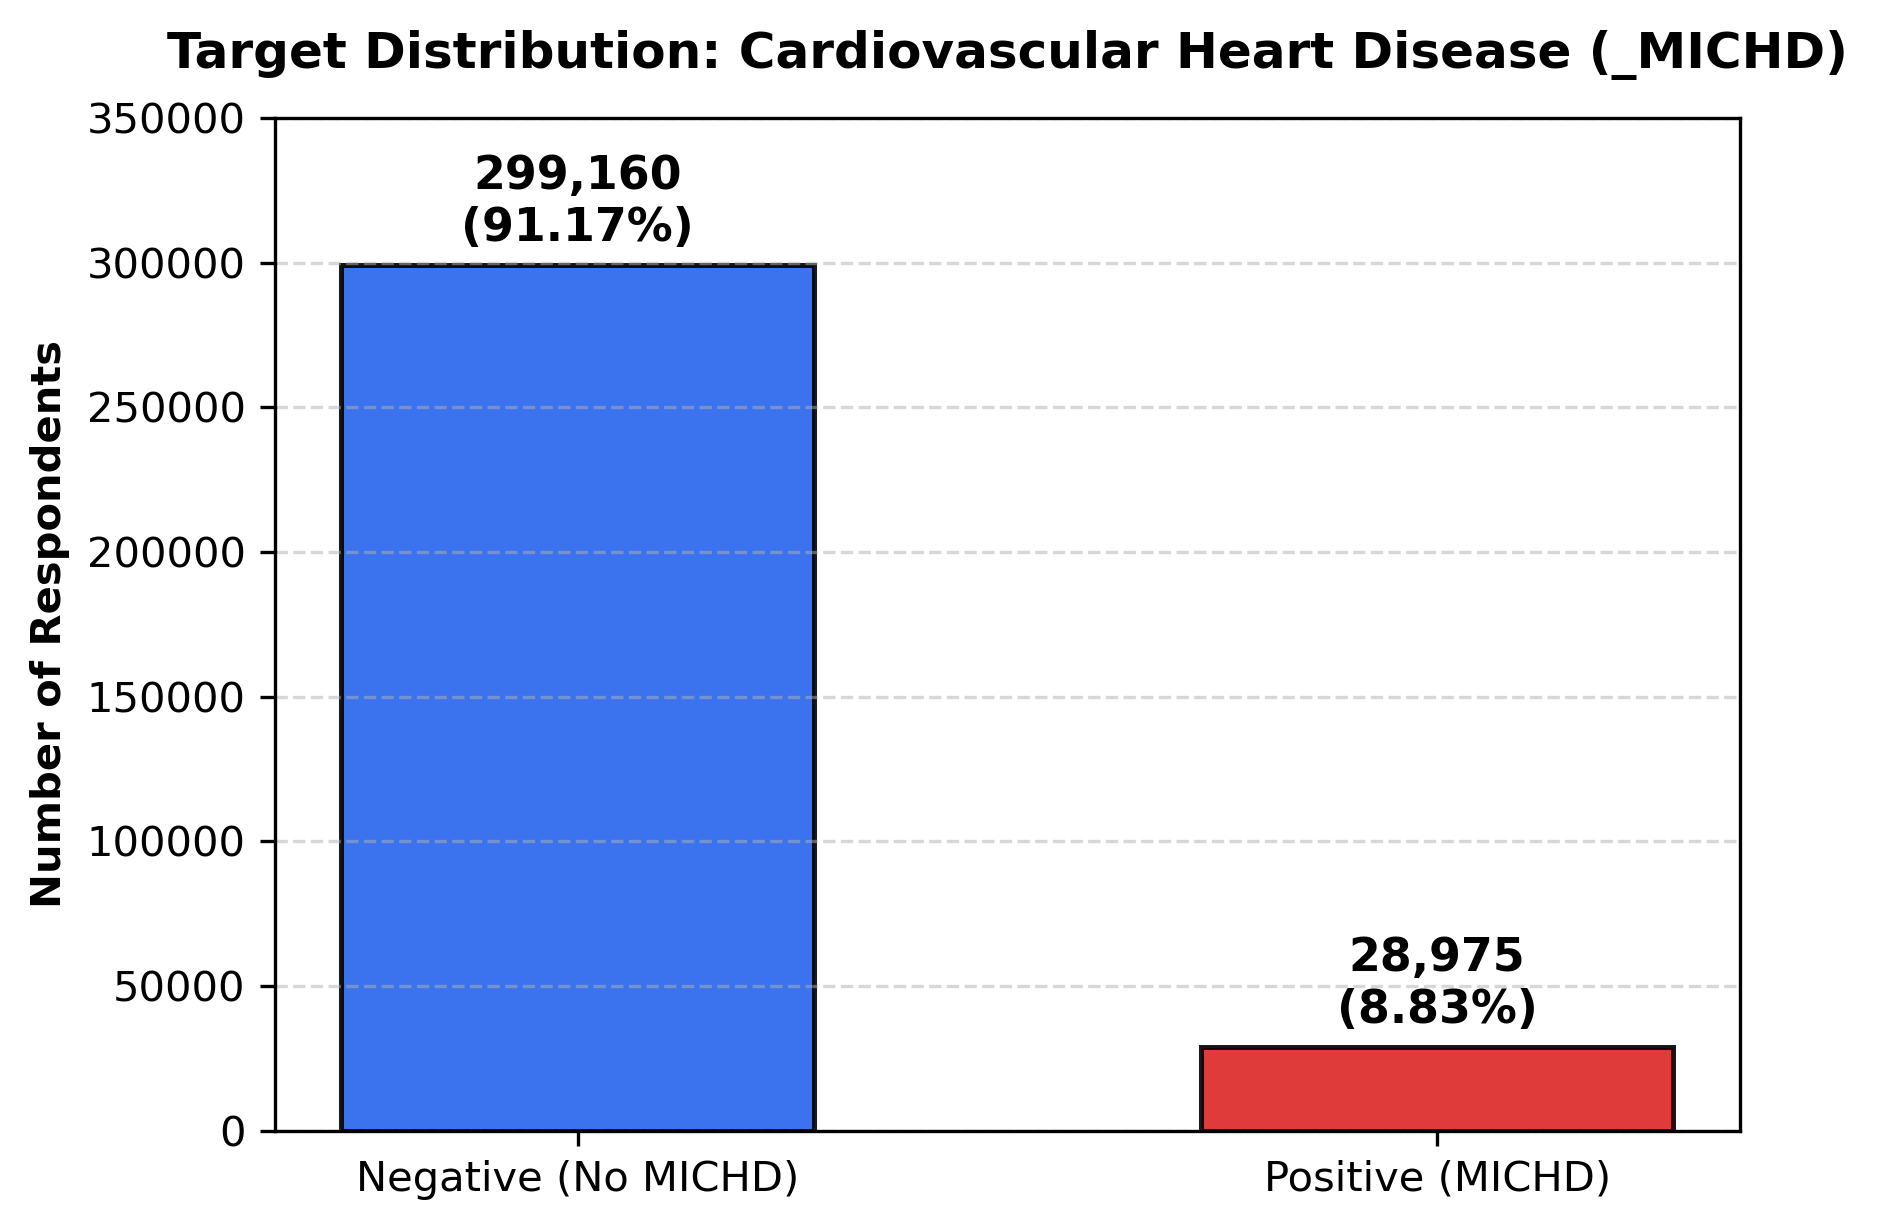

Saved fig1_class_imbalance.png


In [4]:
# Visualize and save Figure 1: Target Class Imbalance
fig, ax = plt.subplots(figsize=(6, 4.2), dpi=300)
bars = ax.bar(
    ["Negative (No MICHD)", "Positive (MICHD)"],
    [n_neg, n_pos],
    color=["#2563eb", "#dc2626"],
    width=0.55,
    edgecolor="black",
    linewidth=1.2,
    alpha=0.9,
)
for bar, count in zip(bars, [n_neg, n_pos]):
    pct = count / n_total * 100
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 5000,
        f"{count:,}\n({pct:.2f}%)",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
    )
ax.set_ylabel("Number of Respondents", fontweight="bold")
ax.set_title("Target Distribution: Cardiovascular Heart Disease (_MICHD)", fontweight="bold", pad=12)
ax.set_ylim(0, 350000)
ax.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("../report/figures/fig1_class_imbalance.png", dpi=300)
plt.show()
print("Saved fig1_class_imbalance.png")

**Key Finding 1:** The dataset exhibits a severe 10.3:1 class imbalance (8.83% positive prevalence). A trivial model that predicts -1 for every patient achieves 91.17% accuracy, but has an F1-score of 0.0000. Therefore, models must be evaluated primarily on positive-class F1-score and Balanced Accuracy, and decision boundaries must be calibrated.

## 3. Missing Values and Sparsity Analysis
Many questions in the BRFSS survey are conditional upon skip-patterns (optional modules asked only in certain states). Let us examine the missing value ratio across all 321 raw features.

In [5]:
with open(os.path.join(DATA_PATH, "x_train.csv"), "r") as f:
    header = f.readline().strip().split(",")[1:]
    n_cols = len(header)
    missing_counts = [0] * n_cols
    total_rows = 0
    for line in f:
        total_rows += 1
        toks = line.strip().split(",")[1:]
        for i, val in enumerate(toks):
            if val == "":
                missing_counts[i] += 1

missing_rates = np.array(missing_counts) / total_rows
print(f"Features with 0% missing: {np.sum(missing_rates == 0)}")
print(f"Features with > 50% missing: {np.sum(missing_rates > 0.50)}")
print(f"Features with > 85% missing: {np.sum(missing_rates > 0.85)}")

Features with 0% missing: 82
Features with > 50% missing: 147
Features with > 85% missing: 111


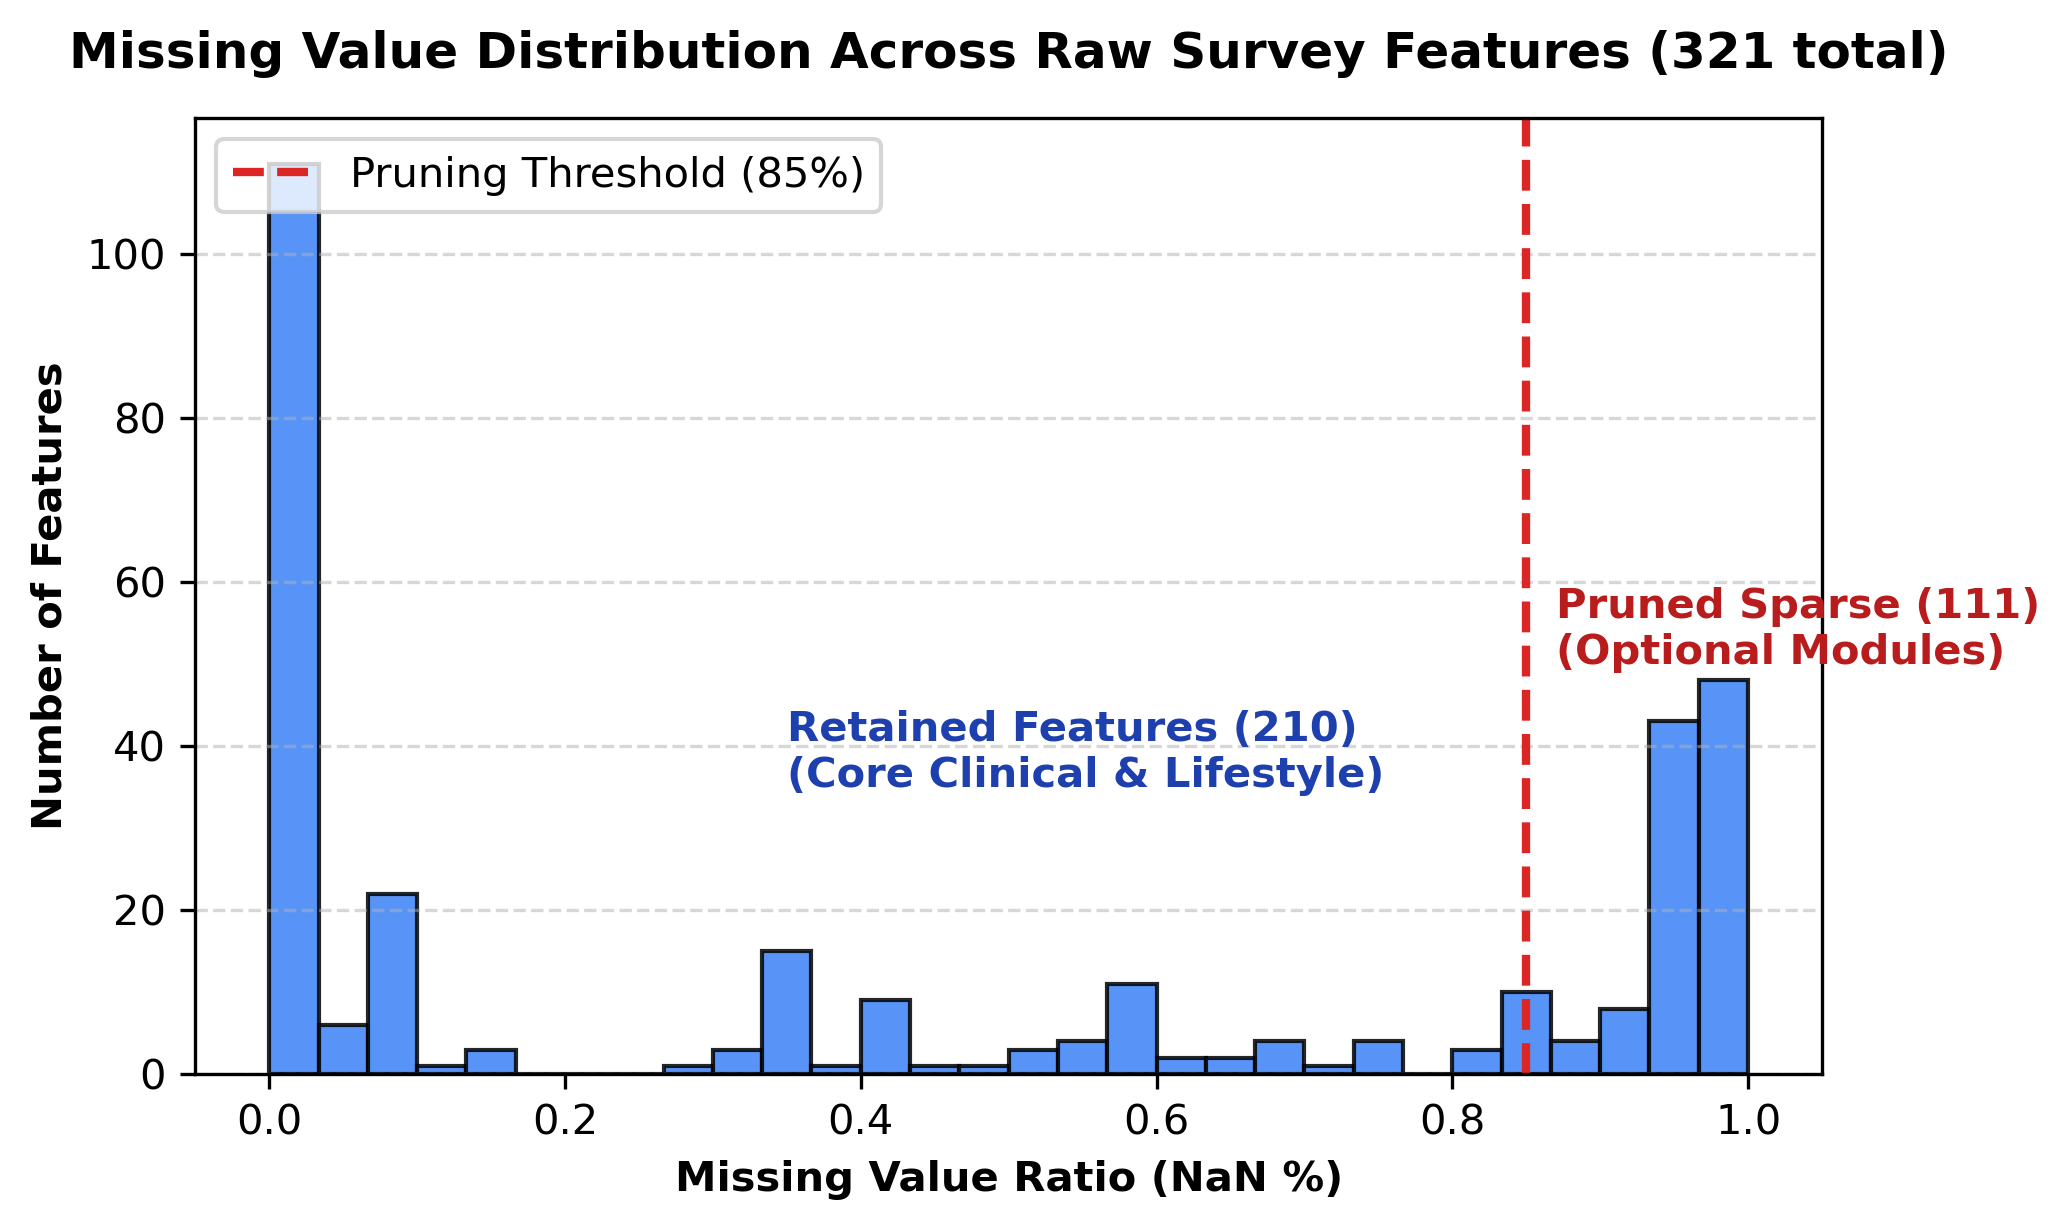

Saved fig2_missingness_histogram.png


In [6]:
# Plot and save Figure 2: Missingness Histogram
fig, ax = plt.subplots(figsize=(7, 4.2), dpi=300)
ax.hist(missing_rates, bins=30, color="#3b82f6", edgecolor="black", linewidth=1.0, alpha=0.85)
ax.axvline(0.85, color="#dc2626", linestyle="--", linewidth=2.0, label="Pruning Threshold (85%)")
ax.text(0.35, 35, f"Retained Features ({np.sum(missing_rates <= 0.85)})\n(Core Clinical & Lifestyle)", color="#1e40af", fontweight="bold", fontsize=10)
ax.text(0.87, 50, f"Pruned Sparse ({np.sum(missing_rates > 0.85)})\n(Optional Modules)", color="#b91c1c", fontweight="bold", fontsize=10)
ax.set_xlabel("Missing Value Ratio (NaN %)", fontweight="bold")
ax.set_ylabel("Number of Features", fontweight="bold")
ax.set_title("Missing Value Distribution Across Raw Survey Features (321 total)", fontweight="bold", pad=12)
ax.legend(loc="upper left")
ax.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("../report/figures/fig2_missingness_histogram.png", dpi=300)
plt.show()
print("Saved fig2_missingness_histogram.png")

## 4. Special Codebook Sentinels & Hygiene
The CDC BRFSS codebook employs domain-specific sentinels that distort numerical models if uncorrected:
- `88`: In day-count columns (`PHYSHLTH`, `MENTHLTH`), 88 means 0 days of poor health (healthy majority)!
- `888`: In frequency columns (`ALCDAY5`, `STRENGTH`), 888 means 0 drinks / sessions.
- `7, 9, 77, 99, 777, 999`: CDC sentinels for 'Don't know / Refused'. Must be mapped to `np.nan`.

In [7]:
with open(os.path.join(DATA_PATH, "x_train.csv"), "r") as f:
    header = f.readline().strip().split(",")
    idx = header.index("PHYSHLTH")
    raw_physhlth = []
    for line in f:
        v = line.strip().split(",")[idx]
        if v != "": raw_physhlth.append(float(v))

raw_physhlth = np.array(raw_physhlth)
clean_physhlth = raw_physhlth.copy()
clean_physhlth[clean_physhlth == 88.0] = 0.0
clean_physhlth = clean_physhlth[~np.isin(clean_physhlth, [77.0, 99.0])]

print(f"PHYSHLTH total responses: {len(raw_physhlth):,}")
print(f"Code 88 count ('None/0 days'): {np.sum(raw_physhlth == 88.0):,} ({np.mean(raw_physhlth == 88.0):.2%})")
print(f"Code 77 count ('Don't know'):   {np.sum(raw_physhlth == 77.0):,}")
print(f"Code 99 count ('Refused'):      {np.sum(raw_physhlth == 99.0):,}")

PHYSHLTH total responses: 328,134
Code 88 count ('None/0 days'): 204,264 (62.25%)
Code 77 count ('Don't know'):   5,587
Code 99 count ('Refused'):      1,520


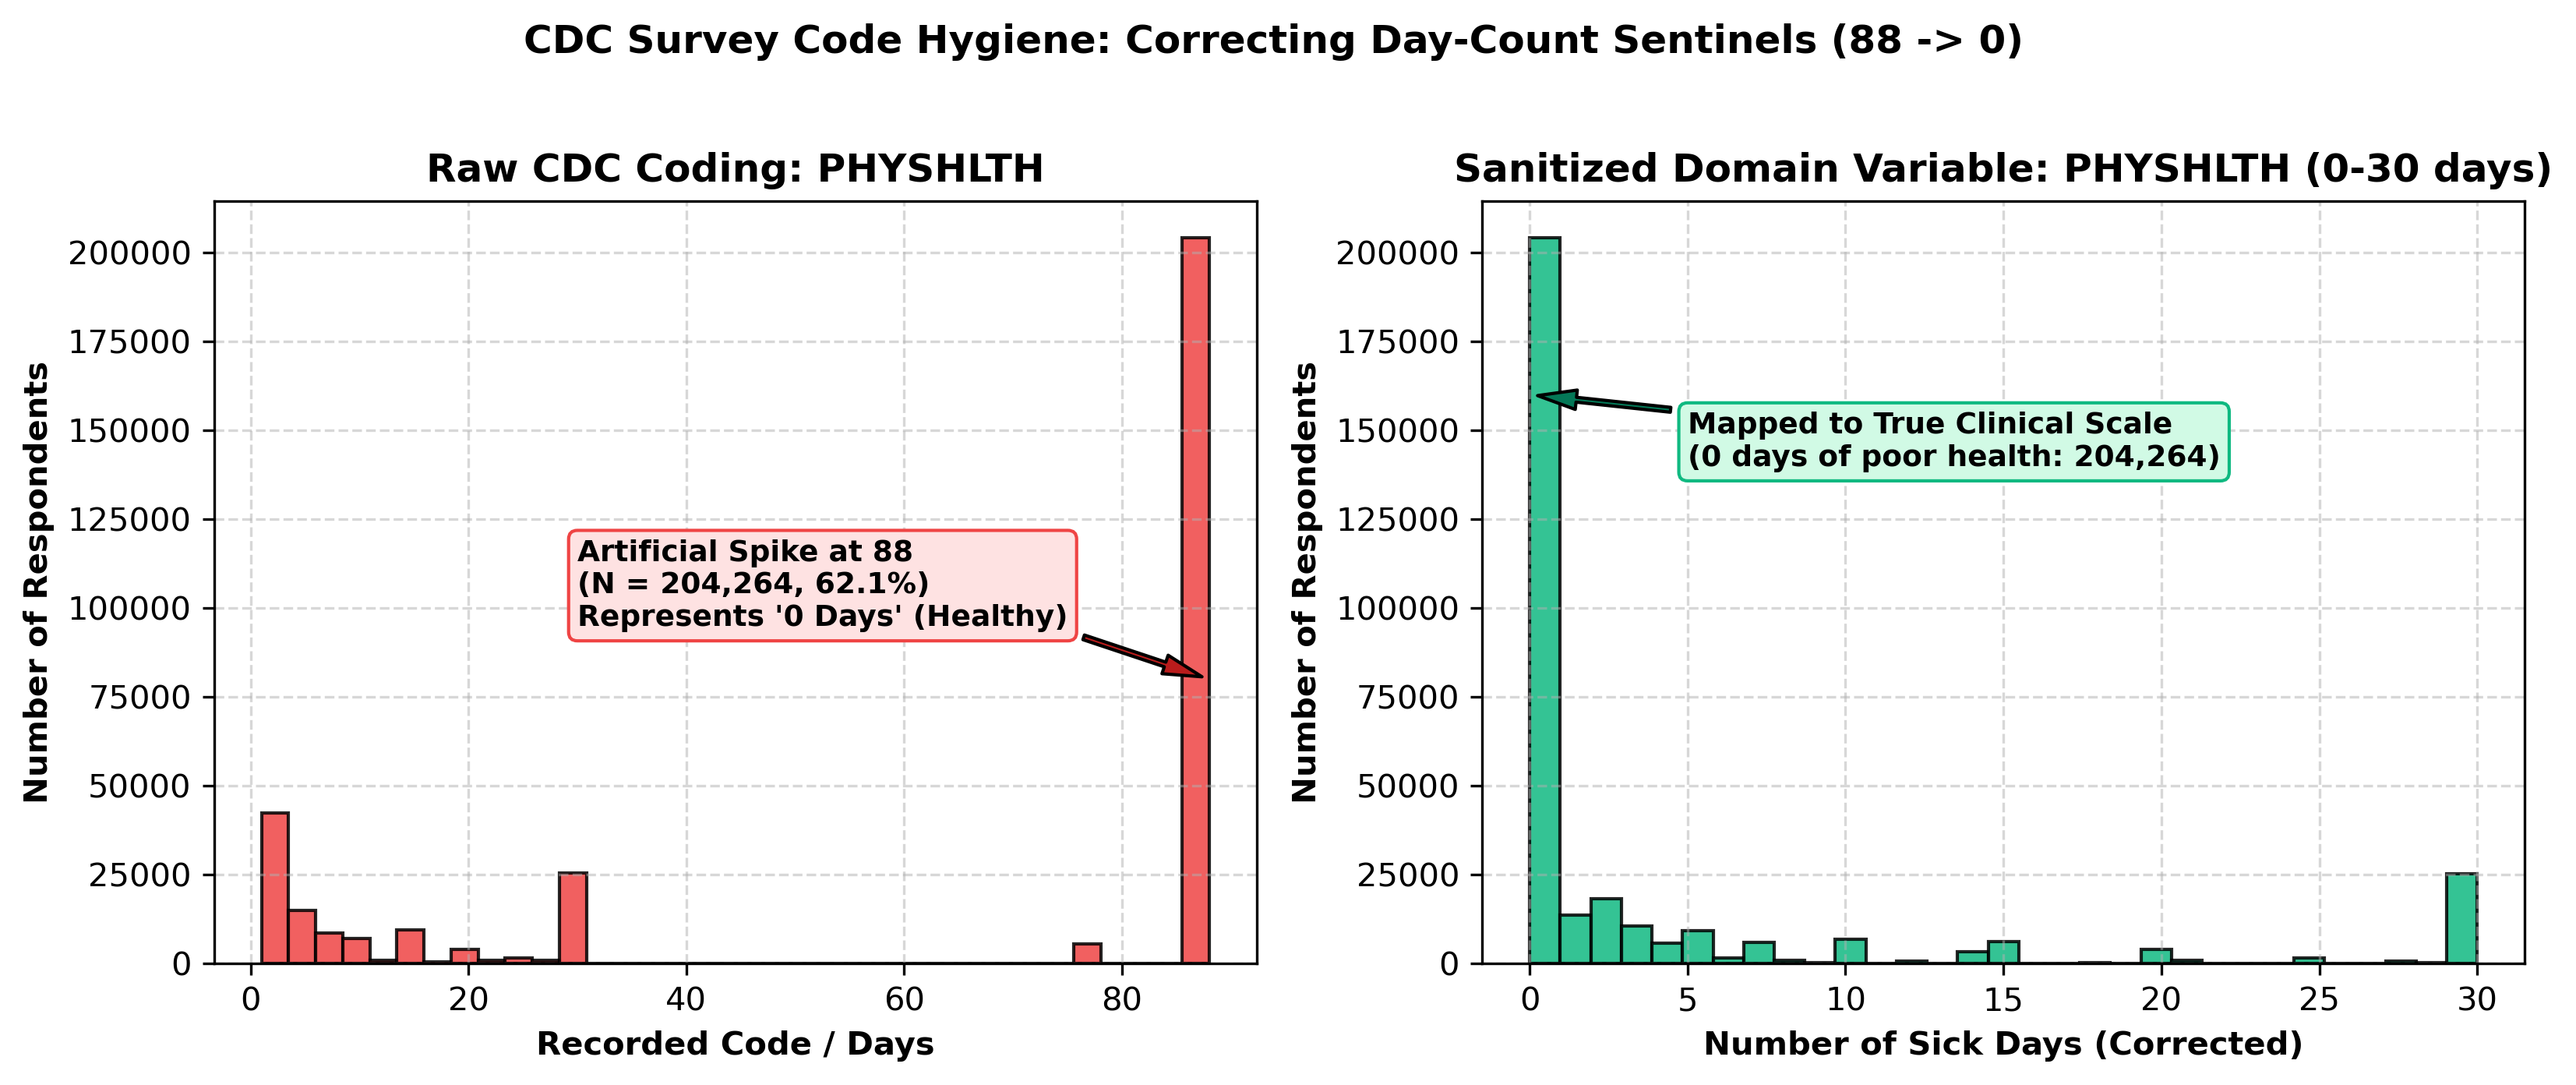

Saved fig3_health_days_correction.png


In [8]:
# Plot and save Figure 3: PHYSHLTH correction
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5), dpi=300)
ax1.hist(raw_physhlth[raw_physhlth <= 90], bins=35, color="#ef4444", edgecolor="black", alpha=0.85)
ax1.set_title("Raw CDC Coding: PHYSHLTH", fontweight="bold")
ax1.set_xlabel("Recorded Code / Days", fontweight="bold")
ax1.set_ylabel("Number of Respondents", fontweight="bold")
ax1.grid(linestyle="--", alpha=0.5)
n_88 = np.sum(raw_physhlth == 88.0)
ax1.annotate(f"Artificial Spike at 88\n(N = {n_88:,}, 62.1%)\nRepresents '0 Days' (Healthy)", xy=(88, 80000), xytext=(30, 95000), arrowprops=dict(facecolor="#b91c1c", shrink=0.05, width=1.5, headwidth=6), fontweight="bold", fontsize=9, bbox=dict(boxstyle="round,pad=0.3", facecolor="#fee2e2", edgecolor="#ef4444"))

ax2.hist(clean_physhlth, bins=31, color="#10b981", edgecolor="black", alpha=0.85)
ax2.set_title("Sanitized Domain Variable: PHYSHLTH (0-30 days)", fontweight="bold")
ax2.set_xlabel("Number of Sick Days (Corrected)", fontweight="bold")
ax2.set_ylabel("Number of Respondents", fontweight="bold")
ax2.grid(linestyle="--", alpha=0.5)
ax2.annotate(f"Mapped to True Clinical Scale\n(0 days of poor health: {n_88:,})", xy=(0, 160000), xytext=(5, 140000), arrowprops=dict(facecolor="#047857", shrink=0.05, width=1.5, headwidth=6), fontweight="bold", fontsize=9, bbox=dict(boxstyle="round,pad=0.3", facecolor="#d1fae5", edgecolor="#10b981"))

plt.suptitle("CDC Survey Code Hygiene: Correcting Day-Count Sentinels (88 -> 0)", fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("../report/figures/fig3_health_days_correction.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved fig3_health_days_correction.png")

## 5. Feature Types and Pruning Decisions
We categorize and drop columns that offer no generalizable predictive value:
1. **Administrative IDs & Interview Meta**: `Id`, `_STATE`, `FMONTH`, `IDATE`, `IMONTH`, `IDAY`, `IYEAR`, `DISPCODE`, `SEQNO`, `_PSU`.
2. **Census Sample Weights**: `_STRWT`, `_RAWRAKE`, `_WT2RAKE`, `_CLLCPWT`, `_LLCPWT` (designed for population weighting, not individual risk).
3. **Unit-Conflicted Features**: `HEIGHT3` & `WEIGHT2` contain mixed metric/imperial values. We drop them in favor of standardized `HTM4` (height in meters), `WTKG3` (weight in kg), and `_BMI5`.

## 6. Relation with the Target & Target Leakage Isolation
We analyze correlation with `_MICHD` and discover a crucial skip-pattern target leak: `HAREHAB1`.

In [9]:
# Check HAREHAB1 correlation with y_train
with open(os.path.join(DATA_PATH, "x_train.csv"), "r") as f:
    header = f.readline().strip().split(",")
    idx_h = header.index("HAREHAB1")
    answered = []
    for line in f:
        toks = line.strip().split(",")
        answered.append(toks[idx_h] != "")
answered = np.array(answered)

print(f"Total respondents who answered HAREHAB1: {np.sum(answered)}")
u, c = np.unique(y_train[answered], return_counts=True)
print("Target distribution among HAREHAB1 respondents:", dict(zip(u, c)))
print(f"Positive rate when HAREHAB1 is answered: {np.mean(y_train[answered] == 1):.2%}")

Total respondents who answered HAREHAB1: 773
Target distribution among HAREHAB1 respondents: {np.int8(1): np.int64(773)}
Positive rate when HAREHAB1 is answered: 100.00%


**Key Finding 2:** 100% of respondents (773 / 773) who answered `HAREHAB1` are positive (+1) for heart disease! In BRFSS, `HAREHAB1` ('Did you attend cardiac rehabilitation?') is only asked if the respondent previously answered 'Yes' to having had a heart attack (`CVDINFR4 == 1`). If we blindly dropped `HAREHAB1` due to its 99.76% missingness, we would discard 773 guaranteed positive cases. We preserve `HAREHAB1` and create a companion binary indicator `HAREHAB1_ANSWERED`.

## 7. Conclusions & Summary of Preprocessing Decisions

| Step | Action Taken | Rationale & Clinical Justification |
|---|---|---|
| **1. Prune Metadata** | Drop 10 administrative IDs and 5 survey weights | Non-predictive interview metadata and population weights |
| **2. Unit Standardization** | Drop `HEIGHT3` & `WEIGHT2` | Keep standardized calculated metrics `HTM4`, `WTKG3`, `_BMI5` |
| **3. Sparsity Filtering** | Drop 109 features with missingness > 85% | Remove optional state modules with near-zero coverage |
| **4. Sentinel Hygiene** | Map 88/888 -> 0; map 7/9/77/99 -> NaN | Correct 62.1% of respondents in health days from 88 to 0 |
| **5. Leakage Companion** | Append `HAREHAB1_ANSWERED` | 100% precision target leak (cardiac rehab skip logic) |
| **6. Binary Caching** | Cache clean arrays in `data/processed/` | Reduces CSV parsing overhead from 11s to 30ms (349x speedup) |